In [1]:
import numpy as np
import pandas as pd
import pickle
import scipy.io as sio
from scipy import signal
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.backends.backend_pdf import PdfPages
%matplotlib inline
import os

In [2]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout, Conv2D, BatchNormalization, Flatten
from tensorflow.keras.optimizers import SGD, RMSprop, Adam


from tensorflow.keras.layers import MaxPooling2D

I0000 00:00:1793602305.188792   46956 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793602305.215152   46956 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793602305.692824   46956 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
def bpf(e, fs, Wn, order):
    #fs = 2000
    #Wn = [0.1, 10]
    b, a = signal.iirfilter(order, Wn, btype = 'bandpass',
                        analog = False, ftype='butter', fs = fs)
    w, h = signal.freqz(b, a, fs=fs)

#    fig, ax = plt.subplots()
#    plt.grid(which="both")
#    ax.plot(w, 20*np.log(abs(h)))
#    ax.axis((0, 100, -100, 10))
#    ax.set_ylabel('Amplitude [dB]')
#    ax.set_xlabel('Freq [Hz]')

    return signal.filtfilt(b, a, e)

In [4]:
def notchf(e, fs, w0, Q):
    b, a = signal.iirnotch(w0, Q, fs)
    return signal.filtfilt(b, a, e)

In [5]:
class EEG_data:
    def __init__(self, label, time, eeg):
        self.time = time
        self.eeg = eeg
        self.label = label

In [6]:
# preprocess function

def preproc_spectro(e, fs=2000, nperseg=200, noverlap=175):
    temp = e.copy()
    f_list, t_list, temp = signal.spectrogram(temp, fs, nperseg=nperseg, noverlap=noverlap) # change to spectrogram
    temp = temp[:61, :] # target frequency is 0-600 Hz
    temp = 20*np.log10(np.abs(temp)) #spectrogram to dB
    temp = temp-np.median(temp[:, 0:8], axis = 1).reshape(-1, 1) #baseline adjustment(median of left 20%)
    temp = (temp-temp.min())/(temp.max()-temp.min()) #normalize to 0-1
    return temp, f_list, t_list

In [7]:
from keras import models

In [8]:
model=models.load_model('model/model_pt1.keras')
model.load_weights('model/model_weight_pt1.weights.h5')

W0000 00:00:1793602340.836136   46956 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [9]:
from tensorflow.keras.models import load_model
from tensorflow.keras import models
import tensorflow as tf

In [10]:
plcm = plt.get_cmap('jet')

In [11]:
from keras.models import Model

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 61, 41, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv3 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 30, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 30, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv3 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,239,493 (31.43 MB)

 Trainable params: 2,746,497 (10.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,492,996 (20.95 MB)

## validate w/ data on day 9

In [13]:
dict_hyp = {
    'train_evolving': 'data/hyp_evolving_pt1.pickle',
    'train_aborted': 'data/hyp_aborted_pt1.pickle',
    'test_evolving': 'data/hyp_evolving_pt1_day9.pickle',
    'test_aborted': 'data/hyp_aborted_pt1_day9.pickle'
}

dict_data = {k: pd.read_pickle(v) for k, v in dict_hyp.items()}

In [14]:
def pred_per_data(k):

    data = dict_data[k]
    list_pred = []

    # 設定
    fs = 2000 #周波数
    nperseg = 200
    noverlap = 175
    backstep = 600
    forwardstep = 600

    for l in data:
        EEG = l.eeg
        list_spectrogram = []
        for k in range(l.np_data.shape[0]):
            t_ind=int(np.where(l.time==l.np_data[k, 4])[0].item())
            if t_ind>=backstep:
                temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy()
                temp, _, _ = preproc_spectro(temp, fs=fs, nperseg=nperseg, noverlap=noverlap)
                list_spectrogram.append(temp)
        list_pred.append(model.predict(np.array(list_spectrogram).reshape(-1, 61, 41, 1)))

    return list_pred



In [15]:
dict_pred = {k:pred_per_data(k) for k in dict_data.keys()}

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━

In [16]:
from matplotlib.colors import ListedColormap

colors=['limegreen', 'crimson', 'snow']
cmap = ListedColormap(colors, name='custum')

In [17]:
def plot_red_green(k, figsize=(8, 8), n_limit=None, title=None, filename=None, dpi=600):

    fs_legend = 7
    fs_xylabel = 10
    l_width = 2
    fs_title = 12

    if title==None:
        title=k
    else:
        title=title


    if n_limit==None:
        list_pred_raw = dict_pred[k]
    else: #n_limit must be smaller than size of predition
        list_pred_raw = dict_pred[k][:n_limit]

    n_max = max([len(pred) for pred in list_pred_raw])
    list_pred = [np.pad(np.where(pred>0.5, 1, 0).flatten(), (0, n_max-pred.size), mode='constant', constant_values=2) for pred in list_pred_raw]
    array_pred = np.array(list_pred)

    fig, ax = plt.subplots(figsize=figsize)

    ax.pcolormesh(array_pred, cmap=cmap, edgecolors='k', linewidth=0.3, shading='flat')
    ax.invert_yaxis()
    ax.set_title(title, fontsize=fs_title)

    xtickslabels = [i for i in range(5, array_pred.shape[1], 5)]
    xticks = [i-0.5 for i  in xtickslabels]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtickslabels)
    ax.xaxis.set_ticks_position('top')
    ax.xaxis.set_label_position('top')

    ytickslabels = [i for i in range(0, array_pred.shape[0], 2)]
    yticks = [i+0.5 for i in ytickslabels]
    ax.set_yticks(yticks)
    ax.set_yticklabels(ytickslabels)

    ax.set_ylabel('ID# of HYP', fontsize=fs_xylabel)
    ax.set_xlabel('number of discharge in each HYP', fontsize=fs_xylabel)

    if filename!=None:
        os.makedirs('figures', exist_ok=True)
        fig.savefig(os.path.join('figures', filename), dpi=dpi)
    plt.show()


    return array_pred



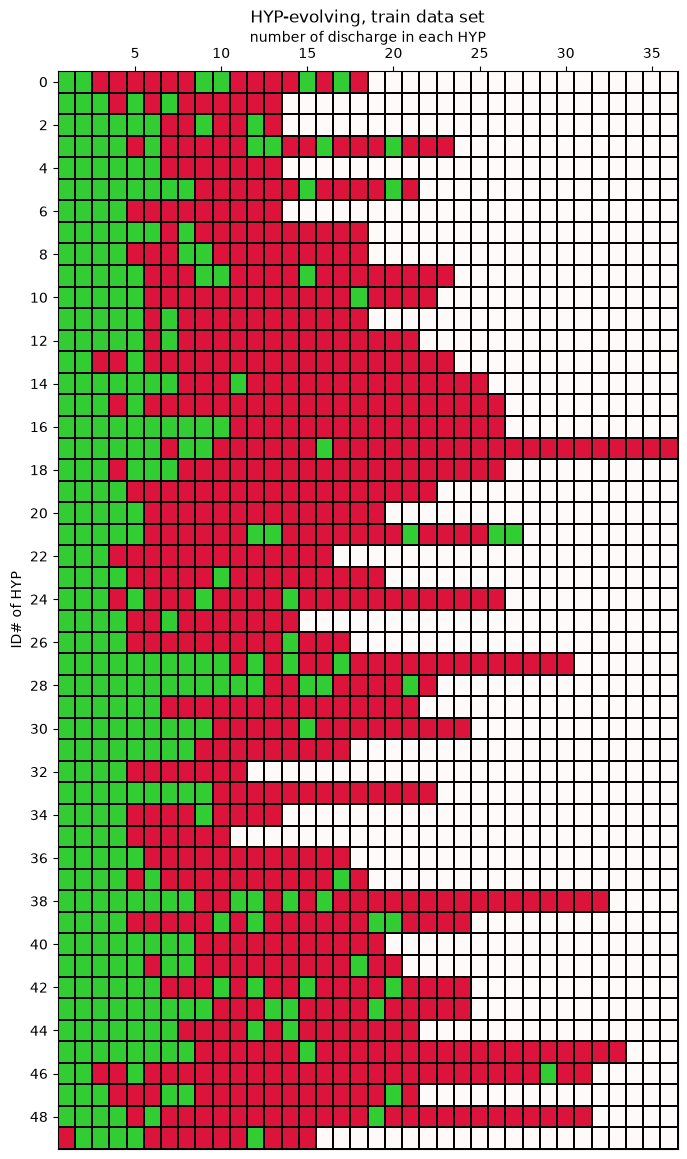

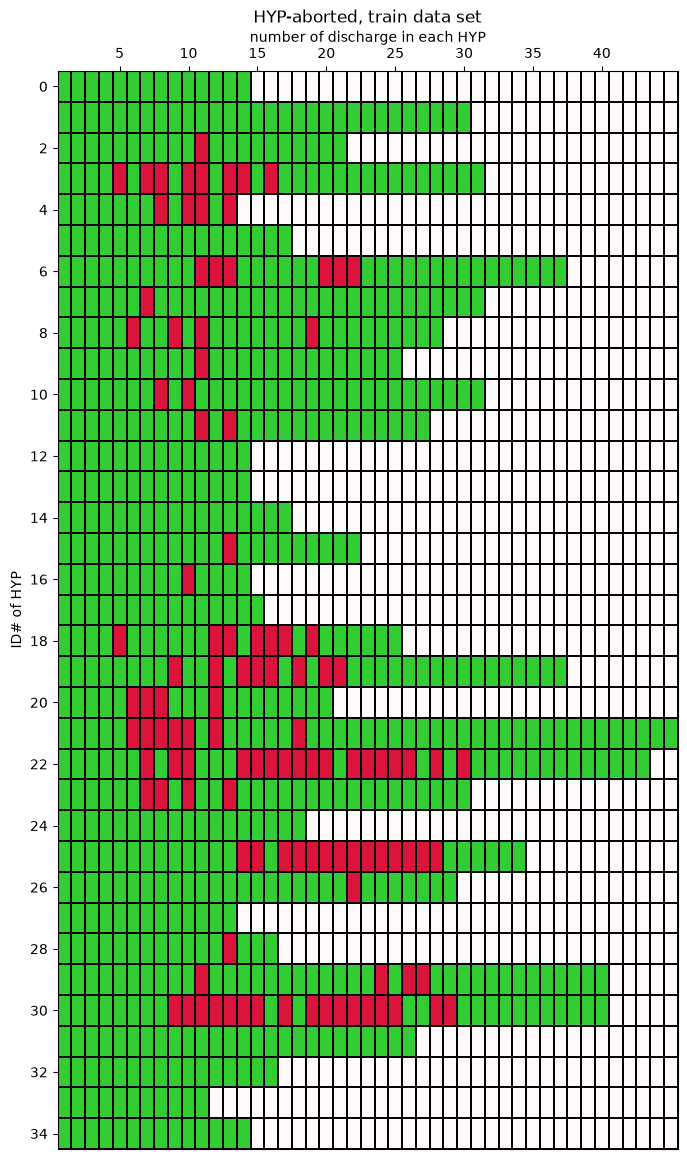

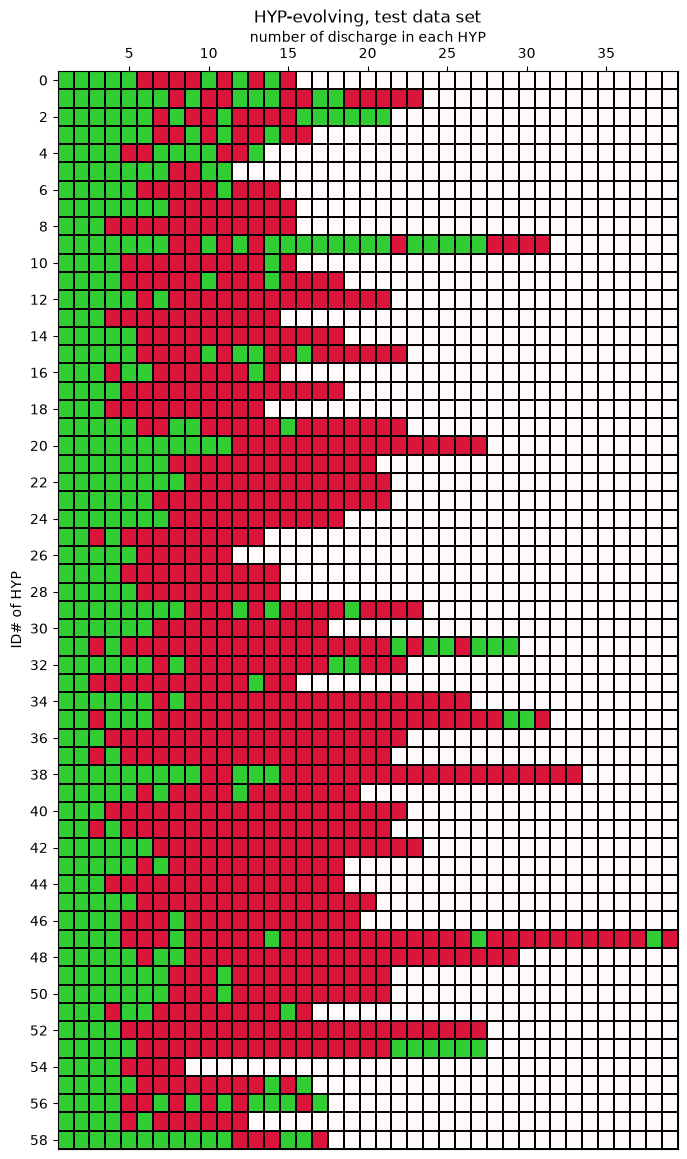

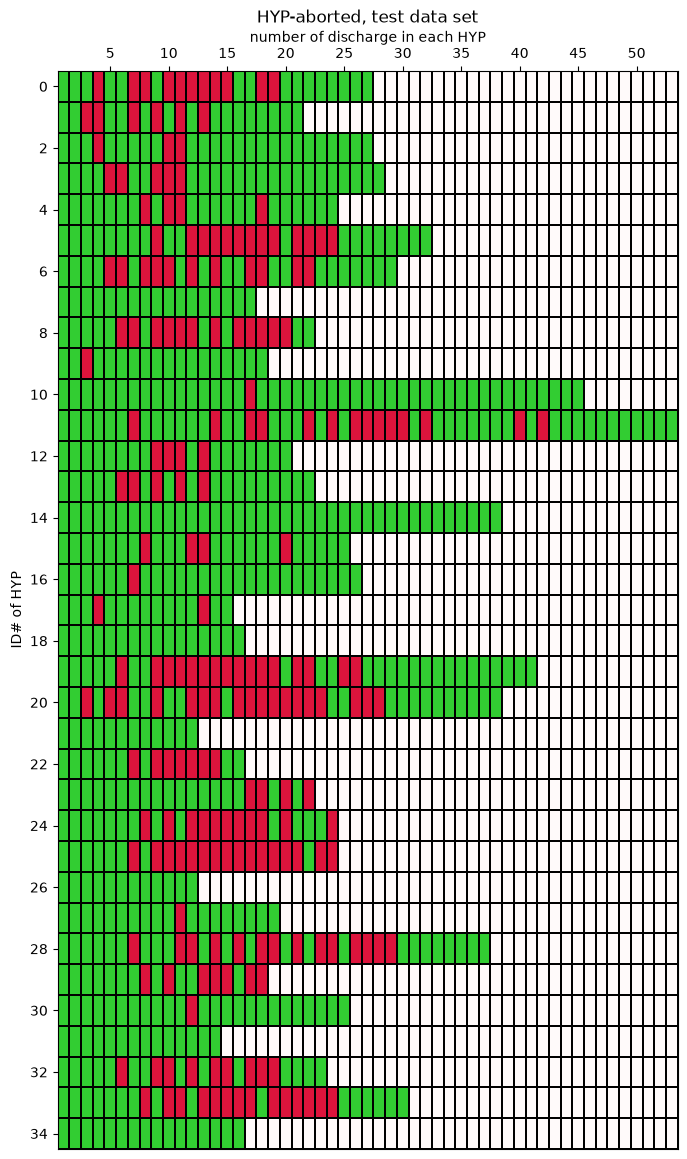

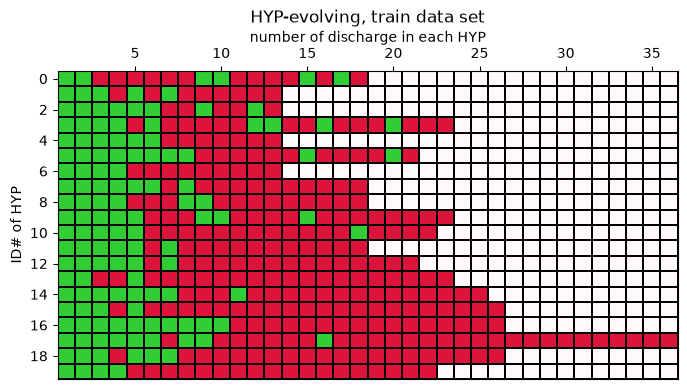

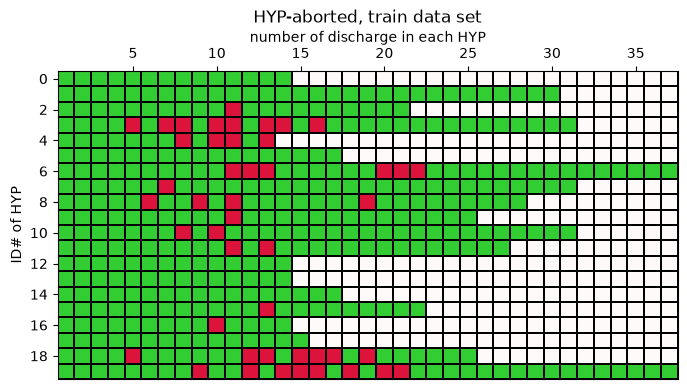

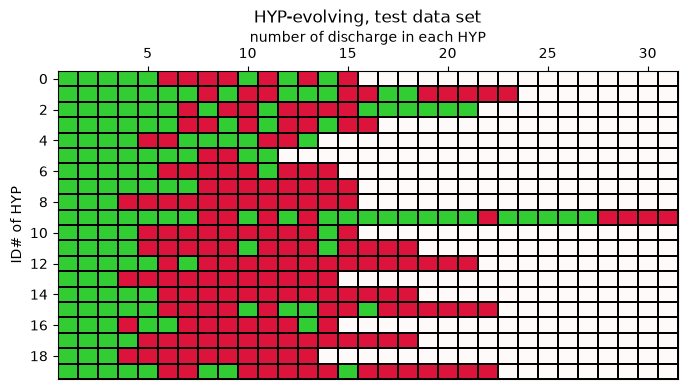

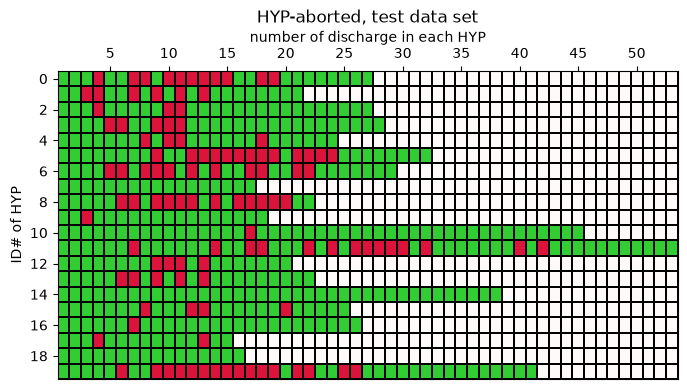

In [18]:
list_keys = ['train_evolving', 'train_aborted', 'test_evolving', 'test_aborted']

for k in list_keys:
    tt, ty = k.split('_')
    title = f'HYP-{ty}, {tt} data set'
    _ = plot_red_green(k, figsize=(8, 14), n_limit=None, title=title, filename='redgreen_pred_'+k+'_full.svg')

for k in list_keys:
    tt, ty = k.split('_')
    title = f'HYP-{ty}, {tt} data set'
    _ = plot_red_green(k, figsize=(8, 4), n_limit=20, title=title, filename='redgreen_pred_'+k+'_10.svg')

In [19]:
def calc_density(arr, window_size):
    kernel = np.ones(window_size)
    return np.convolve(arr, kernel, mode='valid')


In [20]:
# moving average
dict_density = {}
dict_max_density = {}

for k in dict_pred.keys():
    dict_density[k] = [calc_density(np.where(pred>0.5, 1, 0).flatten(), 6) for pred in dict_pred[k]]
    dict_max_density[k] = [a.max().item() for a in dict_density[k]]

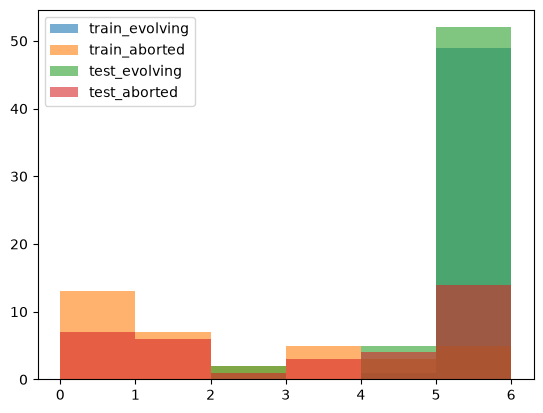

In [21]:
for k in dict_pred.keys():
    plt.hist(dict_max_density[k], label=k, alpha = 0.6, range=(0, 6), bins=6)
plt.legend()
plt.show()

In [22]:
import seaborn as sns

In [23]:
subset_density_test = {k:dict_max_density[k] for k in ['test_evolving', 'test_aborted']}

<Axes: ylabel='Count'>

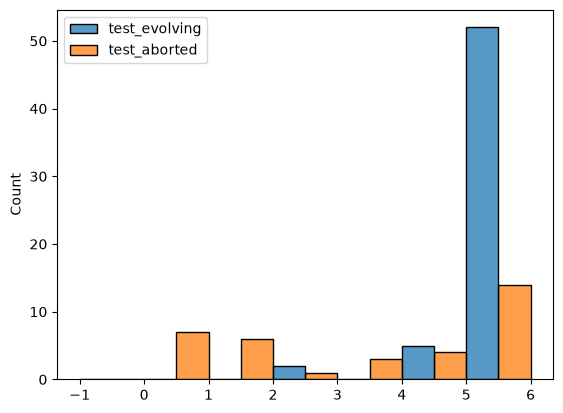

In [24]:
sns.histplot(data=subset_density_test, multiple='dodge', binrange=(-1, 6), bins=7)

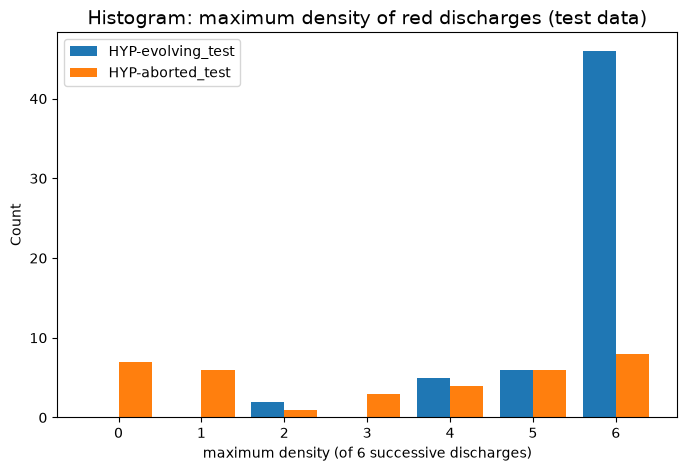

In [25]:
x = np.arange(0, 7)
width = 0.4

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x-width/2, [(np.array(dict_max_density['test_evolving'])==i).sum() for i in range(0, 7, 1)], width, label='HYP-evolving_test')
ax.bar(x+width/2, [(np.array(dict_max_density['test_aborted'])==i).sum() for i in range(0, 7, 1)], width, label='HYP-aborted_test')
ax.legend()
ax.set_title('Histogram: maximum density of red discharges (test data)', fontsize=14)
ax.set_xlabel('maximum density (of 6 successive discharges)', fontsize=10)
ax.set_ylabel('Count', fontsize=10)
plt.savefig('./figures/max_density_hist_test.svg')
plt.show()

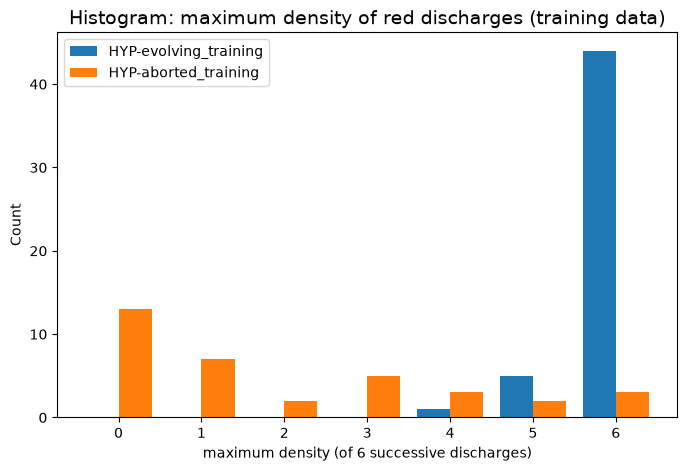

In [26]:
x = np.arange(0, 7)
width = 0.4

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x-width/2, [(np.array(dict_max_density['train_evolving'])==i).sum() for i in range(0, 7, 1)], width, label='HYP-evolving_training')
ax.bar(x+width/2, [(np.array(dict_max_density['train_aborted'])==i).sum() for i in range(0, 7, 1)], width, label='HYP-aborted_training')
ax.legend()
ax.set_title('Histogram: maximum density of red discharges (training data)', fontsize=14)
ax.set_xlabel('maximum density (of 6 successive discharges)', fontsize=10)
ax.set_ylabel('Count', fontsize=10)
plt.savefig('./figures/max_density_hist_training.svg')
plt.show()

In [27]:
threshold = 5

dict_sz_pred = {}
dict_sz_label = {}

for t in ['train', 'test']:
    dict_sz_pred[t] = [m>=threshold for m in dict_max_density[t+'_evolving']]+[m>=threshold for m in dict_max_density[t+'_aborted']]
    dict_sz_label[t] = [1 for i in range(len(dict_max_density[t+'_evolving']))]+[0 for i in range(len(dict_max_density[t+'_aborted']))]

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score, roc_curve, roc_auc_score

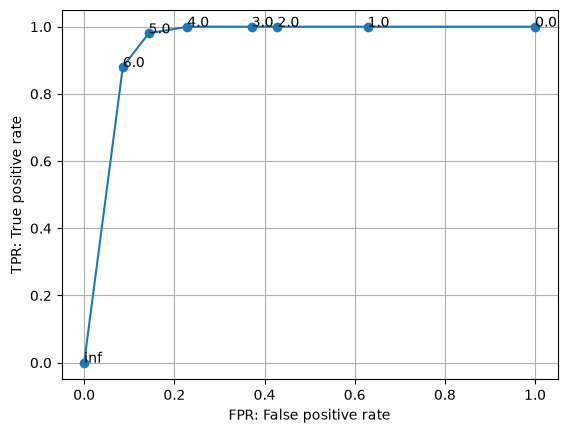

In [29]:
# roc_curve in training

fpr, tpr, thresholds = roc_curve(dict_sz_label['train'], dict_max_density['train_evolving']+dict_max_density['train_aborted'])
plt.plot(fpr, tpr, marker='o')
for x, y, t in zip(fpr, tpr, thresholds):
    plt.annotate(xy=(x, y), text=str(round(t, 2)))
plt.xlabel('FPR: False positive rate')
plt.ylabel('TPR: True positive rate')
plt.grid()
plt.savefig('./figures/ROC_sz_pred_training.svg')

In [32]:
# score in test

dict_score = {}
for key, f in zip(['accuracy', 'precision', 'recall'], [accuracy_score, precision_score, recall_score]):
    dict_score[key] = f(dict_sz_label['test'], dict_sz_pred['test'])
dict_score['f1'] = f1_score(dict_sz_label['test'], dict_sz_pred['test'], average='binary')
dict_score['roc_auc'] = roc_auc_score(dict_sz_label['test'], dict_sz_pred['test'])

cm = confusion_matrix(dict_sz_label['test'], dict_sz_pred['test'])

In [33]:
print(dict_score)

{'accuracy': 0.776595744680851, 'precision': 0.7878787878787878, 'recall': 0.8813559322033898, 'f1': 0.832, 'roc_auc': 0.7406779661016949}


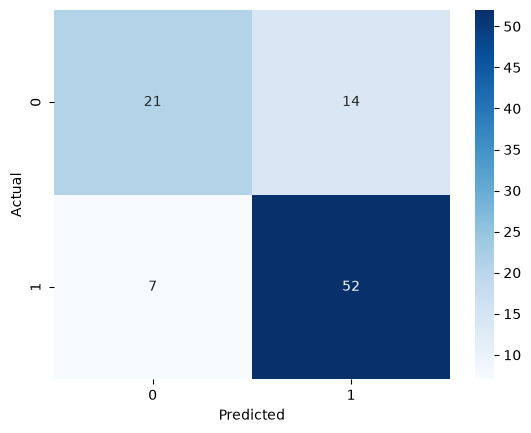

In [34]:
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

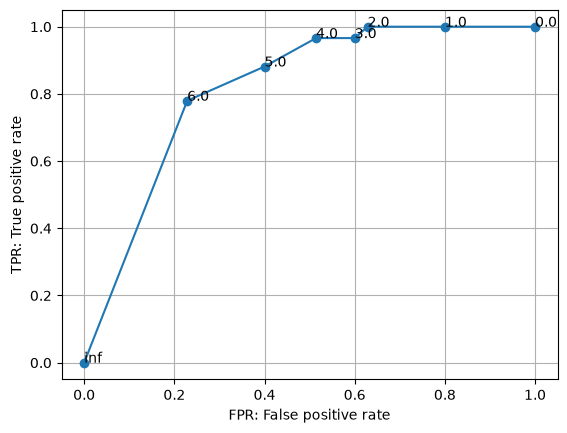

In [36]:
fpr, tpr, thresholds = roc_curve(dict_sz_label['test'], dict_max_density['test_evolving']+dict_max_density['test_aborted'])
plt.plot(fpr, tpr, marker='o')
for x, y, t in zip(fpr, tpr, thresholds):
    plt.annotate(xy=(x, y), text=str(round(t, 2)))
plt.xlabel('FPR: False positive rate')
plt.ylabel('TPR: True positive rate')
plt.grid()
plt.savefig('./figures/ROC_sz_pred_test.svg')